# IV. How to: FitDarkCurrentProcess
## From the raw data to Fit the Dark current

# Fitting Dark Current

This is an example of how to fit the dark current.

The distribution of pixels values in a CCD comes from the convolution of the pixel charge with the pixel readout noise. The pixel charge is the sum of a Poisson-distributed leakage current accumulated during the exposure and a ionized signal charge (from a ionizing particle that interacts with the silicon target). The readout noise is paramtrized from the pixel value distribution of blanks and overscans, and found to be well-described by the convolution of a Poisson with average $\lambda$ and a Gaussian of standard deviation $\sigma$.

If the input image contains tracks, the best is to estimate the dark current only using the first two single electron peaks where contribution from any ionizing particle is almost negligigle. In this case the pixel value distribution (in units of ADU) for the n-first single electron peaks is derived as

\begin{equation}
    \mathcal{N} \cdot \sum_{n=0}^{n-th} \mathcal{P}(n- \frac{\mu_{0}}{k} ; \lambda) \circledast \mathcal{G}(n-\frac{\mu_{0}}{k},\sigma) \qquad\qquad\qquad\qquad [1]
\end{equation}

where

* $n$ corresponds to the number of electrons of the corresponding single electron peak
* $k$ is the relative calibration constant (or gain) in units of ADU/e$^{-}$
* $\lambda$ is the Poisson parameter in units of $e^{-}/$pix
* $\mu_{0}$ corresonds to the center of the zero-charge single electron peak (in units of ADU); if pedestal have been done, should be around 0 ADU.
* $\sigma$ is the single electron resolution, the noise, i.e. the standard deviation of the gaussian to be the same for all fitted peaks (in units of ADU/pix).

This is done by `FitDarkCurrentProcess` provided by `pysimdamicm.processes.skipper_analysis` which contains a large number of [processes](https://ncastell.web.cern.ch/ncastell/pysimdamicm/howtouse_analysis.html#process-by-process)  related to skipper images.


This process use [ROOT.TH1F.Fit](https://root.cern.ch/root/htmldoc/guides/users-guide/FittingHistograms.html) to fit the pixel charge distribution to equation 1.



## Configuration Parameters for `FitDarkCurrentProcess`

#### `image` config param

Same idea as in the previous process (`PedestalSubtractedProcess`). 

The image to be used to fit the dark current can calibrated image (i.e. `image_mean_compressed_pedestal_subtracted_e` pixel charge in units of $e^{-}/$pix, but not introduced yet) or the one from the pedestal subtracted process (i.e. `image_mean_compressed_pedestal_subtracted`, in units of ADU/pix). The later is the one by default.

#### `method` config param

Only one method is availablre right now

#### `in_overscan` config param

Set to use the overscan cols region instead of the active retion (which is the one by default!)

#### `n_peask` config param

Number of single electron peak to fit (from 0, up to `n_peaks` -1 )

####  `n_sigma_fit` config param

To fit the image in units of ADU and without knowing the calibration constant this parameter is quite important. The fitting process is recursive, and the spectral window size change from trail to trail. This number `n_sigma_fit` is used to define the spectral window and using only those pixel charge within the espectral window:

\begin{equation*}
    q_{row,col} \in [-k , (N_{peaks} - 1)*k + n \cdot \sigma_{0}]
\end{equation*}

where 
* `n` is given by `n_sigma_fit` and 
* $k$ is `calibration`
* $N_{peaks}$ is `n_peaks`
* $\sigma_{0}$ is the standard deviation obtained only using the pixels with charge velow 1$e^{-}$ (i.e. $q_{i,j}/k < 1$)

#### `do_calibration` config param

Set this parameter to also fit the calibration constant (or gain). The fit algorithm is assuming the image is in units of ADU and the calibration constant will be also fitted. 

What you can also do also, is use the already calibrated image, and still fit the gain. In this case, the fitted calibration constant should be around 1. This is used to bettter estimate the already know calibration constant which perhaps changed for whatever reason.

#### `calibration` config param

If `do_calibration` is set, just the starting point of the calibration constant.

#### `lambda_poisson`, `mu_gauss` config params

The starting point for the fitting algorithm. If nothing is passed, a first estimation is done internally

#### `binning_size` config param

The binning size for the histogram used to fit the dark current. If negative, the binning size will be integer of $2 \cdot \sqrt{ N_{pixels} }$


# Index

In this howto there are two sections:
* **Section A**: How to from a Python Interpreter
* **Section B**: How to brom bash

In both cases, we will do the same (fit the dark current), but using two different approaches. The first option allows yo to get to know and go deeper into the different sub-modules of `pysimdamicm`, while the second is the use of `pysimdamicm` as a black box through the `panaSKImg` script. 


## A. How to from a Python Interpreter

### Following previous howto 


1. Load all modules needed for this **howto**
2. Define which data to be used
3. Load Configuration file (see [how to I](./I_howto_RawData.ipynb))
4. Create a RawData object (see [how to I](./I_howto_RawData.ipynb))
5. Compress image (see [how to II](./II_howto_CompressSkipperProcess.ipynb))
6. Subtract pedestal (see [how to III](./III_howto_PedestalSubtractedProcess.ipynb))
7. Finally, fit the dark current (this how to)

### 1. Load all modules needed for this howto

In [1]:
%matplotlib inline

# loading damicm module
import pysimdamicm as ccd

# loading other packages
import ROOT

Welcome to JupyROOT 6.14/06


### 2. Define which data to be used

##### For this example, an image from the Compoton is used. This image has 2000 skips

In [2]:
# variable pointing where my#### data is
path_to_raw_data = "/data/workdir/compton/data/calidaq_backup/DataTaking/Am241/skip_2000_img/"

# pattern file name
img_pattern_file_name = "Image_Am241_Source_55_{}.fits"
# absolute path to the file name
file_name = "{}/{}".format(path_to_raw_data,img_pattern_file_name)

print("\nMy images follows the patter file name:\n {}\n".format(file_name.format("*")))


My images follows the patter file name:
 /data/workdir/compton/data/calidaq_backup/DataTaking/Am241/skip_2000_img//Image_Am241_Source_55_*.fits



### 3. Load configuration file

#### Using the default configuration json file, available in the `pysimdamicm` package

In [3]:
# path where our JSON file is
cfg_file = "{}/json/panaSKImg_configuration.json".format(ccd.__path__[0])

# False to interpret the JSON file as a configuration for data instead of simulations (default one) 
cfg = ccd.utils.config.Config(cfg_file, simulations=False)

In [4]:
print(ccd.utils.config.json.dumps(cfg.configuration['input'], indent=4, sort_keys=True))

{
    "convention": {
        "Ncols": "NAXIS1",
        "Npbin": "NPBIN",
        "Nrows": "NAXIS2",
        "Nsbin": "NSBIN",
        "Nskips": "NDCMS",
        "ampl": "AMPL",
        "exposure_time": "MEXP",
        "read_time": "MREAD"
    },
    "image": {
        "active_region_cols": null,
        "active_region_rows": null,
        "axis_to_compress": 1,
        "correct_leach_bug": true,
        "correct_polarity": false,
        "extensions": 0,
        "id_col_end": -1,
        "id_col_start": 0,
        "id_row_end": -1,
        "id_row_start": 0,
        "id_skip_end": -1,
        "id_skip_start": 3,
        "n_cols_overscan": 15,
        "n_cols_prescan": 2,
        "n_rows_overscan": 0,
        "n_rows_prescan": 0,
        "skip_image": true
    },
    "scp": {}
}


### 4. Create a RawData object

#### Load the image using the BuilderRawData function. This will return an object of type RawData

Remember that this step only read all necessary parameters from the header (`convention`) as well as the image. However, it does not create the different regions for the overscan, prescan and sensor.  For that, use the function member of the RawData (see 3.1).


In [5]:
ccd.io.rawdata.__verbose__ = False
rdata = ccd.io.rawdata.BuilderRawData(file_name.format('skip_1'), cfg.configuration['input'])

Correction INFO. Correcting data for Leach bug:
 	 the first two column moved to the end,
 	 move one-row down (only the two last columns).



#### 3.1 An extra step is needed to read all regions of an image: overscan, prescan and sensor regions

Internally what this function does is the creation of a boolean array for each region. This boolean array with the same size than the full image, should be used against the object `rdata.image_mean_compressed` to select only regions we are insterested in by using `numpy.ma.array`. The object `rdata.image_mean_compressed` is the averaged skip image (see next steps).

In [6]:
rdata.prepare_data()

RawData INFO.
 *********************************************************************** 
 ********* Define mask for sensor and over/pre-scan regions 'Image_Am241_Source_55_skip_1.fits' ********* 
 *********************************************************************** 

 * Active region: 
		rows=0:60
		cols=2:260

 * Overscan  in cols: 
		rows=0:60
		cols=260:275

 * Prescan  in cols: 
		rows=0:60
		cols=0:2

 * NO Overscan  in rows

 * NO Prescan in rows
 ***********************************************************************. 



#### Our data image 

The attribute `image` of `rdata` contains our data image. It is an array of 3 dimensions if the input file corresponds to an skipper image, and a 2D is is the already averaged image.

The dimensions are for:
* number of rows
* number of cols
* number of skips

In [7]:
rdata.image.shape

(60, 275, 2000)

This image has 60 rows, 275 columns and each pixels has been measured 2000 times.

### 5. Compress image

#### Create the averaged image using the process class CompressSkipperProcess


In [8]:
comp = ccd.processes.skipper_analysis.CompressSkipperProcess()

In [9]:
comp.id_skip_start = 10
comp.execute_process(rdata)
print("Total pixel charge: ", rdata.image_mean_compressed.sum())

Process <CompressSkipsProcess> INFO. Compressing raw image data using the following statistics: ['mean', 'std']
     - used skip range 10:2000
     - image (60, 275, 1990) have been reduced to 60x275

Total pixel charge:  80913010.51758793


### 6. Subtract pedestal

#### Estimate the pedestal and remove it from the image using the process class PedestalSubtractionProcess


In [10]:
ped = ccd.processes.skipper_analysis.PedestalSubtractionProcess()

In [11]:
%matplotlib inline
# full image
ped.in_overscan = True
ped.axis = "row"
ped.n_sigma_to_mask = 10
ped.use_mad = True
# set method
ped.method = 'gauss_fit'
ped.execute_process(rdata)

Process <PedestalSubtractionProcess> INFO. Equalize the image by substracting the pedestal.
   - using overscan region
   - masking image: mask all pixels with qij > median + 10 MAD
   - pedestal as the mu of a the fitted gaussian to the zero-charged peak (axis row)
  Pedestral subtracted image recorded as data member image_mean_compressed_pedestal_subtracted of rawdata 




### 7. Fit the dark current

#### $\color{red}{\text{FitDarkCurrentProcess}}$ is the process class to fit the dark current 

To fit the dark current we will use the process class `FitDarkCurrentProcess` provided by `pysimdamicm.process.skiper_analysis`.


In [12]:
dcfit = ccd.processes.skipper_analysis.FitDarkCurrentProcess()

### How can we configure this process?

The user can change the following configuration parameters:

In [13]:
dcfit.info()

<FitDarkCurrentProcess> with sequence id 30.
 List of public data members: 
	 * __sequence_id__ = 30 
	 * __verbose__ = False 
	 * binning_size = -1 
	 * calibration = 20 
	 * do_calibration = True 
	 * fit_options = QSE 
	 * id_col_end = nan 
	 * id_col_start = nan 
	 * id_row_end = nan 
	 * id_row_start = nan 
	 * id_skip_end = nan 
	 * id_skip_start = nan 
	 * image = mean_compressed_pedestal_subtracted 
	 * in_overscan = False 
	 * lambda_poisson = 0.05 
	 * method = root 
	 * mu_gauss = 0.0 
	 * n_peaks = 2 
	 * n_sigma_fit = 10 
	 * save_image = False 
	 * save_plots = False 
	 * sigma_gauss = 0.2 


#### Configuration Parameters for Pedestal Subtracted Process:

This process has a lot of parameters and for that a lot of combinations. 
*$\color{orange}{\text{Be careful when using them,  altough some options are allowd, this does not mean that they all make sense!}}$*

### Example 1: Fitting the Dark Current as well as the gain

In [14]:
dcfit = ccd.processes.skipper_analysis.FitDarkCurrentProcess()

dcfit.__verbose__ = False

dcfit.do_calibration = True
dcfit.binning_size = 0.15

dcfit.calibration = 1.0
dcfit.n_peaks = 2
dcfit.n_sigma_fit = 10
dcfit.mu_gauss = 0.0
dcfit.sigma_gauss = 0.03
dcfit.fit_options = "QSE"

dcfit.execute_process(rdata)


Process <FitDarkCurrentProcess> INFO. Fit the n-first peaks to estimate the dark current and the calibration constant.
 Fitting within the spectral range: (-1.0,6.911518343376828)
 Spectral window for Fit:     -1.0 6.911518343376828
   Fit DC Results:
     * Normalization = 1522.700649484212 +/- 18.070330457859217
     * zero electron peak = -0.043982750038745744 +/- 0.8401458537534615
     * single electron resolution  = 0.6631077783899875 +/- 2.0932711043002876
     * dark current = 0.23639260047656263 +/- 2.1868499746571044
     * new gain = 0.9162150168728558 +/- 1.387001540690021
 ---- RE-FITTING starting with gain=0.9162150168728558 (realtive error: 0.09144685645200591, trial: 1)

Process <FitDarkCurrentProcess> INFO. Fit the n-first peaks to estimate the dark current and the calibration constant.
 Fitting within the spectral range: (-0.9162150168728558,6.695211964088324)
 Spectral window for Fit:     -0.9162150168728558 6.695211964088324
   Fit DC Results:
     * Normalization =

Info in <TCanvas::MakeDefCanvas>:  created default TCanvas with name c1


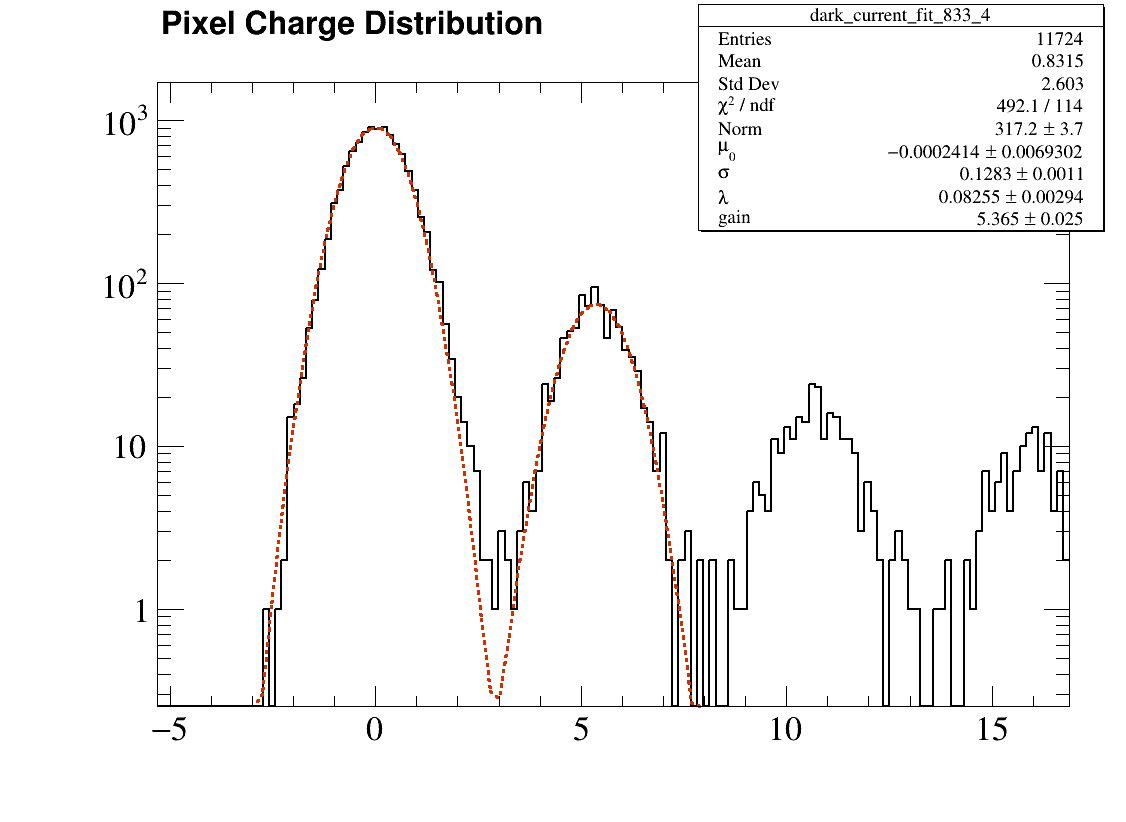

In [15]:
c = ROOT.TCanvas()
c.Draw()
dcfit.hist.Draw()

c.SetLogy()
c.Update()
c.Draw()

## Summary

In [ ]:
%matplotlib inline

# loading damicm module
import pysimdamicm as ccd
import ROOT

cfg = ccd.utils.config.Config("{}/json/panaSKImg_configuration.json".format(ccd.__path__[0]),  simulations=False)

ccd.io.rawdata.__verbose__ = False
image_file_name = "/data/workdir/compton/data/calidaq_backup/DataTaking/Am241/skip_2000_img/"+\
    "Image_Am241_Source_55_skip_1.fits"
rdata = ccd.io.rawdata.BuilderRawData(image_file_name, cfg.configuration['input'])
rdata.prepare_data()

## compress image with the default funcitons: mean, and std; and skip 10 first measurements
comp = ccd.processes.skipper_analysis.CompressSkipperProcess()
comp.id_skip_start = 10
comp.execute_process(rdata)

## substract pedestal using overscan and row by row (default)
ped = ccd.processes.skipper_analysis.PedestalSubtractionProcess()
ped.__verbose__ = True
ped.use_mad = True
ped.method = 'gauss_fit'
ped.execute_process(rdata)

## fit dark current to the first two peaks
dcfit = ccd.processes.skipper_analysis.FitDarkCurrentProcess()
dcfit.__verbose__ = False
dcfit.do_calibration = True
dcfit.binning_size = 0.15
dcfit.calibration = 1.0
dcfit.n_peaks = 2
dcfit.n_sigma_fit = 10
dcfit.mu_gauss = 0.0
dcfit.sigma_gauss = 0.03
dcfit.fit_options = "QSE"
dcfit.execute_process(rdata)

## due to notebook issues the DC plot must be explicitely plot (to be the plot integretad into the document)
c = ROOT.TCanvas()
c.Draw()
dcfit.hist.Draw()
c.SetLogy()
c.Update()
c.Draw()

## B. How to from bash: panaSKImg


The main script for analysis is `panaSKImg` also provided by `pysimdamicm`. It is a python3 script to apply a chain of processes over a real data CCD image. Find more information [here](https://ncastell.web.cern.ch/ncastell/pysimdamicm/howtouse_analysis.html).


To $\color{green}{\text{fit the dark current}}$ we can also use `panaSKImg`. We will only need 
* a configuration JSON file and 
* the input image file.

Here is an example of how to run the same as in **Sect. A** (*How to from a Python Interpreter*), but with `panaSKImg`:

```console
    panaSKImg --json <config_file.json> "image_file" --display --verbose -o .
```

`display` and `verbose` will display all plots created along the process.

### How to set the parameters of each process?
Two possible ways:

* Using the configuration file
* Or using command lines

It is possible to use both the json file and command lines. $\color{green}{\text{The command lines have preference over those of the json file.}}$

#### by using the JSON file

This has to be done in the configuration file. [Here](./howto_Config.html) you can find information about the full JSON file.


```json
      "FitDarkCurrentProcess":
      {
          "image":"pedestal_subtracted",
          "method":"root",
          "do_calibration":false,
          "n_peaks":2,
          "n_sigma_fit":2,
          "mu_gauss":0.0,
          "sigma_gauss":0.2,
          "lambda_poisson":0.05,
          "fit_options":"QSL",
          "save_as":true
      },
```

All these parameters have been explained along this howto.

#### by command line

Almost all parameters has a command line to be pass as an argument of `panaSKImg`. Run

```console
    panaSKImg --help
```

for help on the command lines. Here the output of the help related with `FitDarkCurrentProcess`



```console
*** For Process FitDarkCurrentProcess ************************** :
  --dc-axis DC_AXIS     Axis to fit the dark current.
  --n-elec N_ELEC       Number of single eletron peaks to use to fit the dark
                        current
  --n-sigma-fit N_SIGMA_FIT
                        Number of sigmas to define the spectral window to
                        estimate the initial values of all paramters to be fit
  --mu-gauss MU_GAUSS   Initial value for the position of the single electron
                        peak at 0 electrons
  --sigma-gauss SIGMA_GAUSS
                        Initial value for the electronic noise (e-/pix)
  --lambda-poisson LAMBDA_POISSON
                        Initial value for the dark current (e-/pix)
  --fit-options FIT_OPTIONS
                        Options for the fitting see ROOT::TGraph::Fit
  --do-calibration      Set if the calibration constant from user should be
                        used (in this case, use calibration option to pass its
                        value)

```



#### `sequence` is mandatory

Remember that the parameter `sequence` of the `process` section of the JSON file must be informed. You can do that using the command line **-s** as follows

```console
    panaSKImg --json <config_file.json> "image_file" --display --verbose -o . -s CompressSkipperProcess,PedestalSubtractionProcess,FitDarkCurrentProcess
```

To list all possible process you can just run

```console
    panaSKImg --list-process help
```


In [16]:
%sx panaSKImg --list-process help

['',
 ' Beginning new ROOT session',
 'OBJ: TStyle\tModern\tModern Style : 0 at: 0x5591e501af00',
 '\t CalibrationProcess',
 '\t ChargeLossPlot',
 '\t ClusterFinder',
 '\t CompressSkipperProcess',
 '\t ContinuousReadout',
 '\t CreateFitsImage',
 '\t DarkCurrent',
 '\t Diffusion',
 '\t ElectronicNoise',
 '\t FFTNoisePlot',
 '\t FitCalibrationConstant',
 '\t FitDarkCurrentProcess',
 '\t PedestalSubtractionProcess',
 '\t PixelSaturation',
 '\t PixelizeSignal',
 '\t RNvsNskipsPlot',
 '\t SignalPatternRecognition']